### VSCode Terminal:- Run this commands
```python
mkdir AIML_GCP_BATCH
```
---
```python
cd AIML_GCP_BATCH
```
---
### Create one .py file -> create_gcs_bucket.py
---
```python
pip install --upgrade google-cloud-storage
```
---
### For upgradation:- 
```python
python.exe -m pip install --upgrade pip
```
### Then again:-
```python
pip install --upgrade google-cloud-storage
```
---
```python
gcloud init
```
### Then:-
> Press 1 -> Reinitialize

> Select GCP Account
---


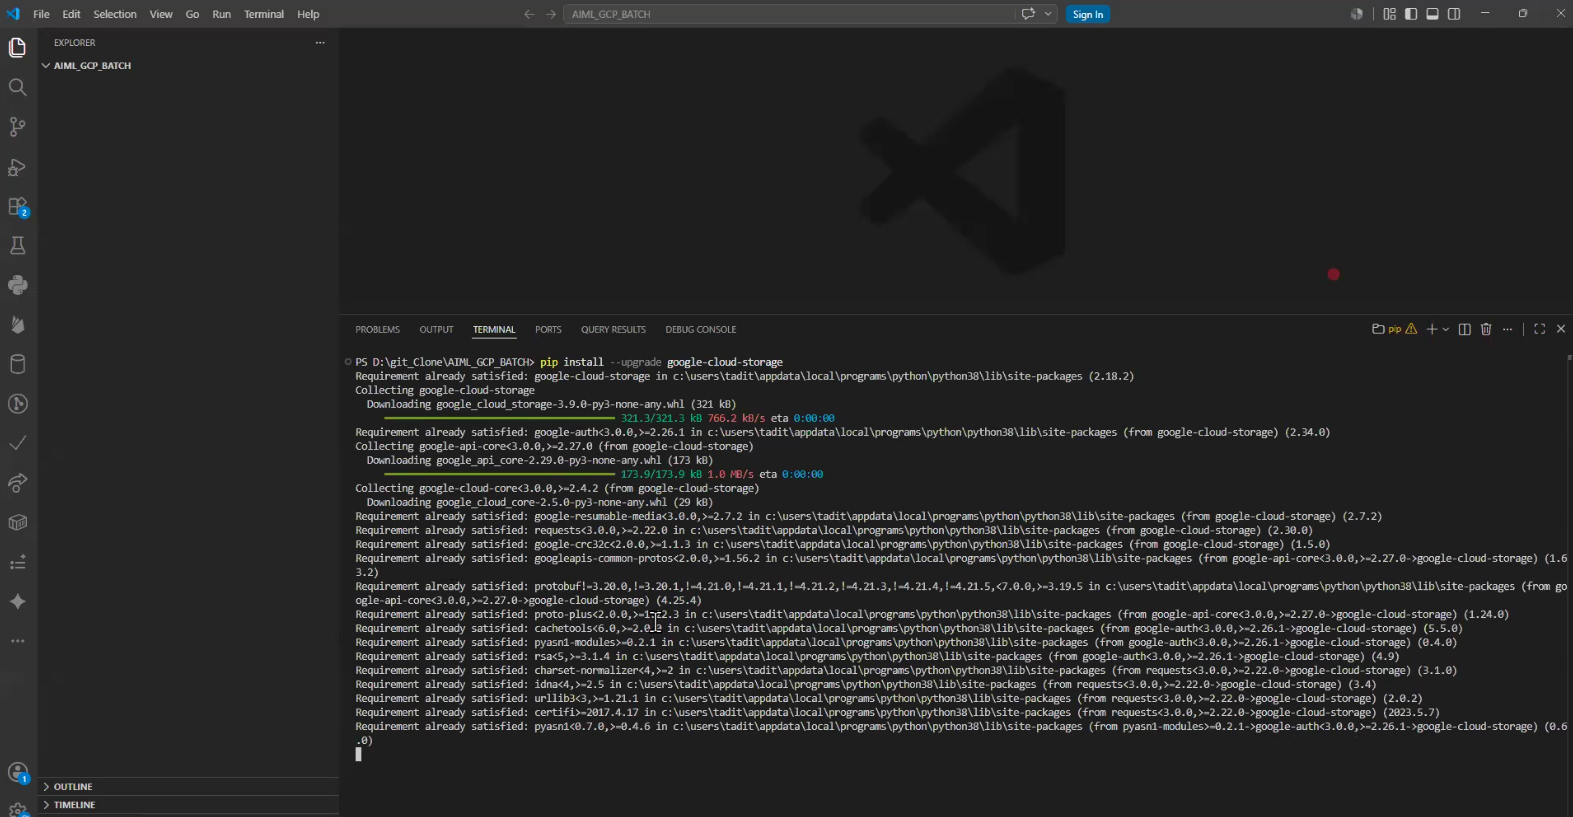

# GCS Operations — Python Client Library

How to perform the following GCS operations using the **`google-cloud-storage`** Python client library:

1. Create a bucket
2. List buckets
3. Upload an object
4. Delete an object
5. Copy an object
6. Move an object

## Prerequisites
- Python package `google-cloud-storage` installed.
- Application Default Credentials configured:
  ```bash
  gcloud auth application-default login
  ```

In [ ]:
# Install the Python client library (uncomment if not already installed)
# !pip install google-cloud-storage --quiet


---
## 1. Create a Bucket

```python
from google.cloud import storage

def create_bucket_class_location(bucket_name):
    """
    Creates a new bucket with a specified storage class and location.
    """

    # Create Storage Client
    storage_client = storage.Client()

    print("Storage Client Object :", storage_client)

    # Create Bucket Object
    bucket = storage_client.bucket(bucket_name)

    print("Bucket Object :", bucket)

    # Set Storage Class
    bucket.storage_class = "COLDLINE"

    # Create Bucket in US Region
    new_bucket = storage_client.create_bucket(
        bucket,
        location="US"
    )

    print(
        "Created bucket {} in {} with storage class {}".format(
            new_bucket.name,
            new_bucket.location,
            new_bucket.storage_class,
        )
    )

    return new_bucket


# -----------------------------
# Main Program
# -----------------------------
if __name__ == "__main__":

    bucket_name = "gcp-aiml-bwt-dummytest"   # Bucket name must be globally unique

    val = create_bucket_class_location(bucket_name)

    print("-" * 40)
    print(val)
    print("-" * 40)

```    
---
### Commands:-
```python
gcloud auth application-default login
```
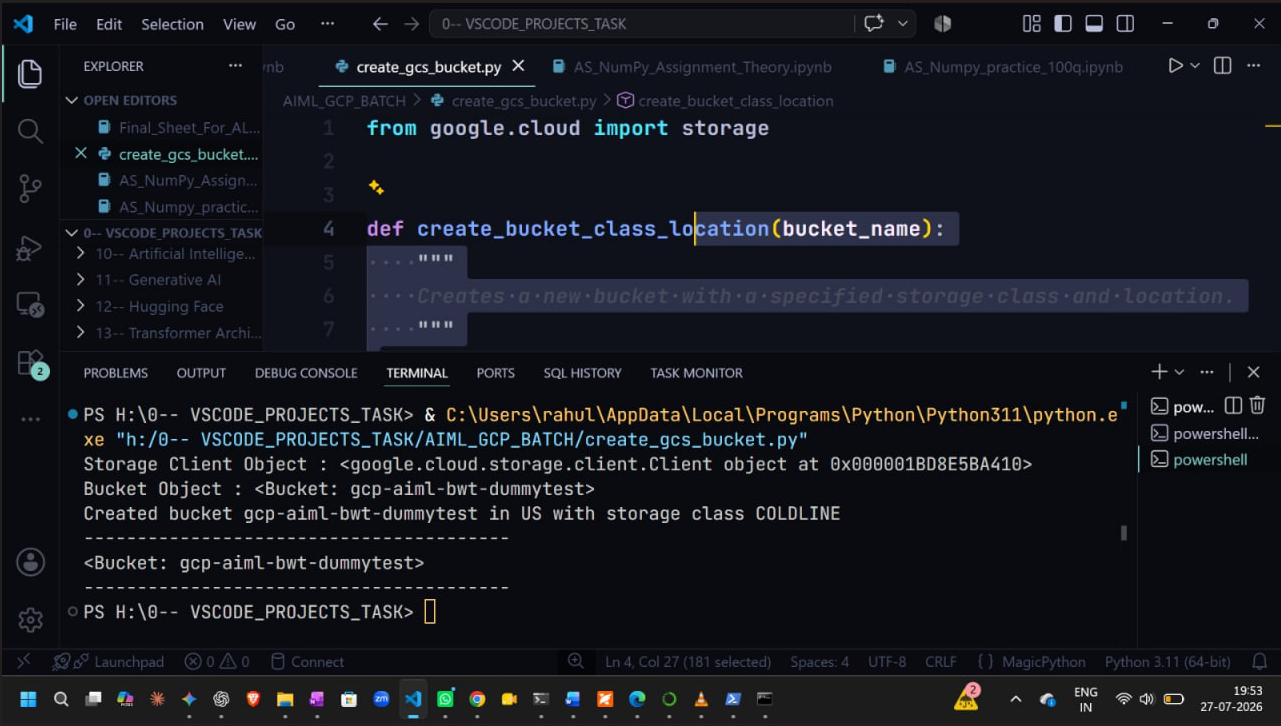

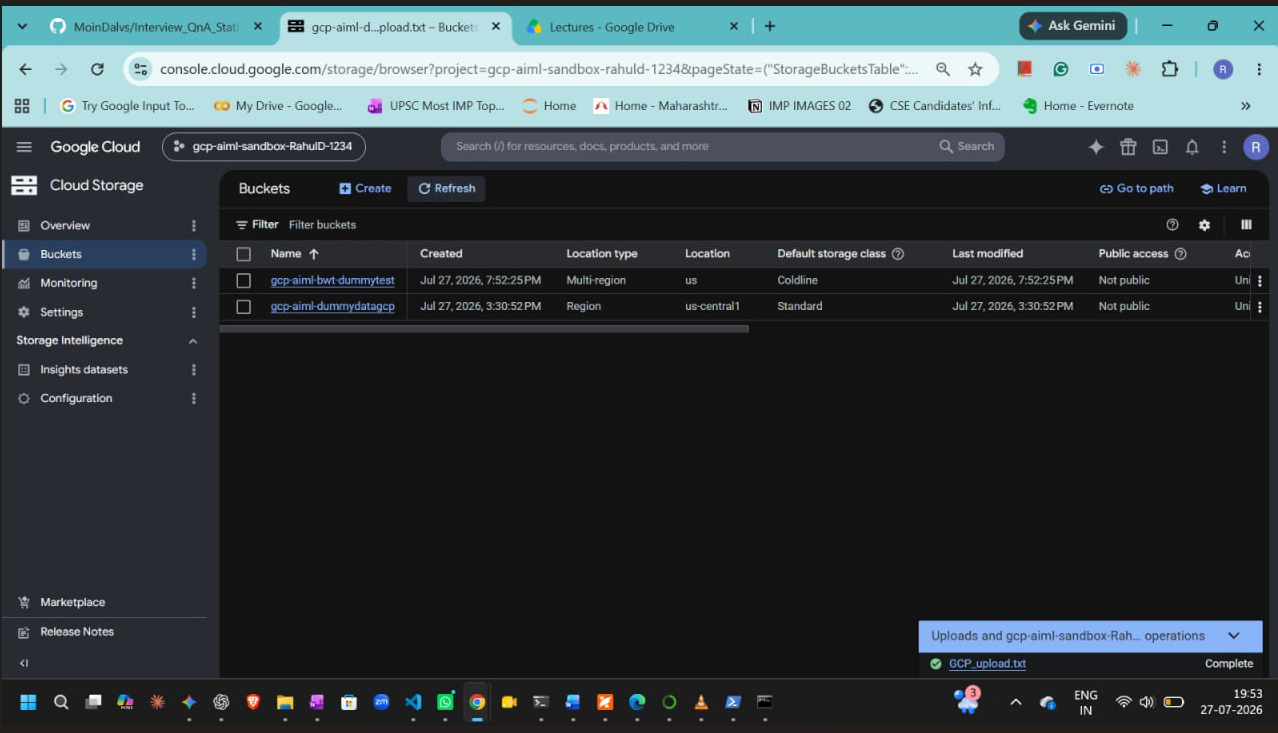

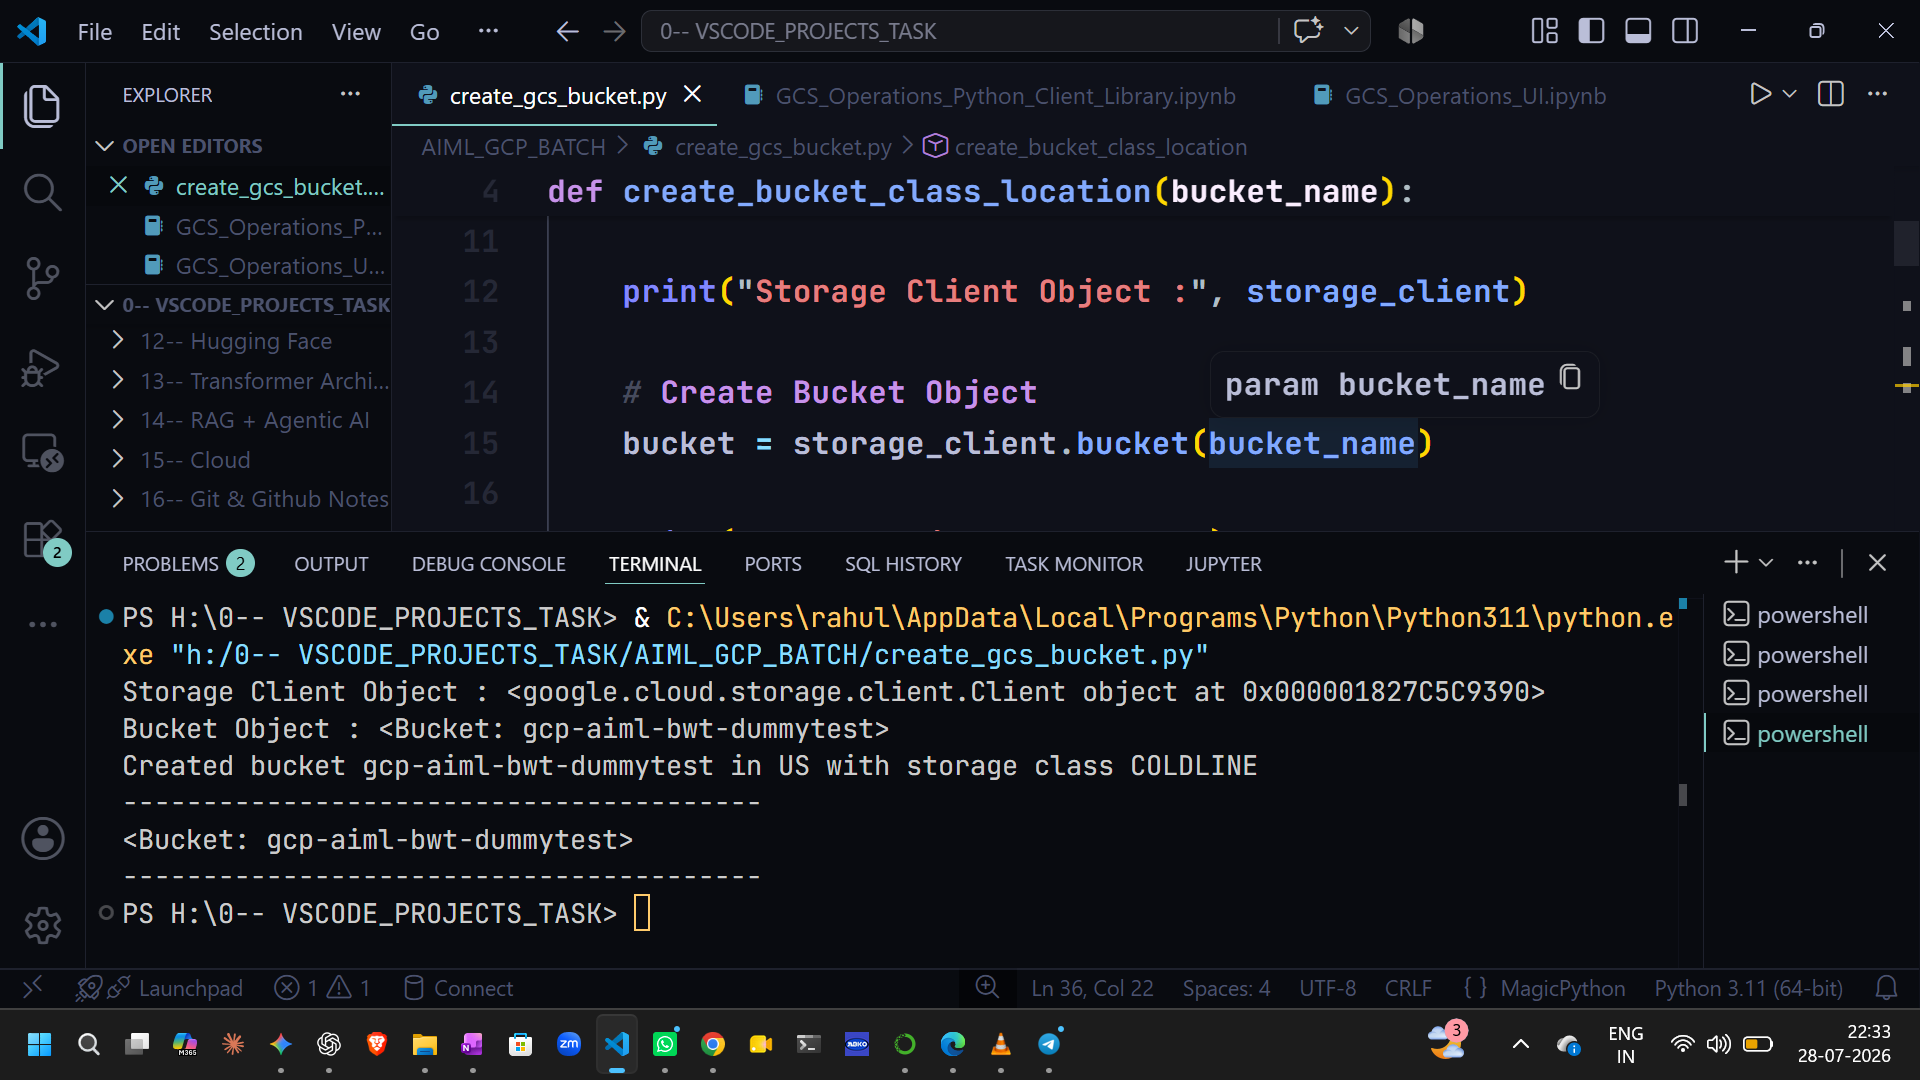

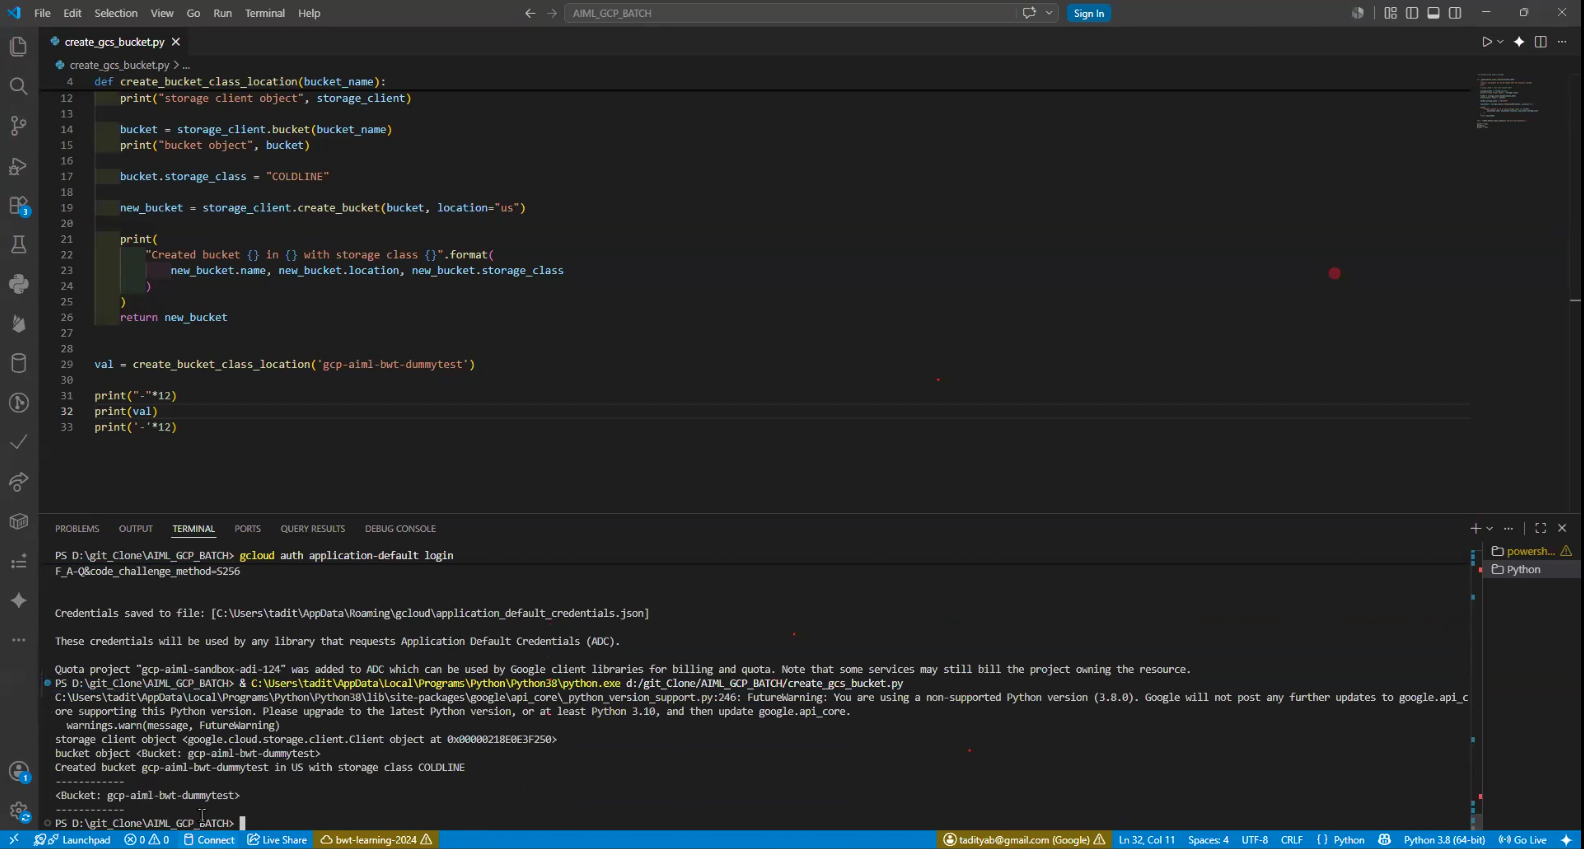

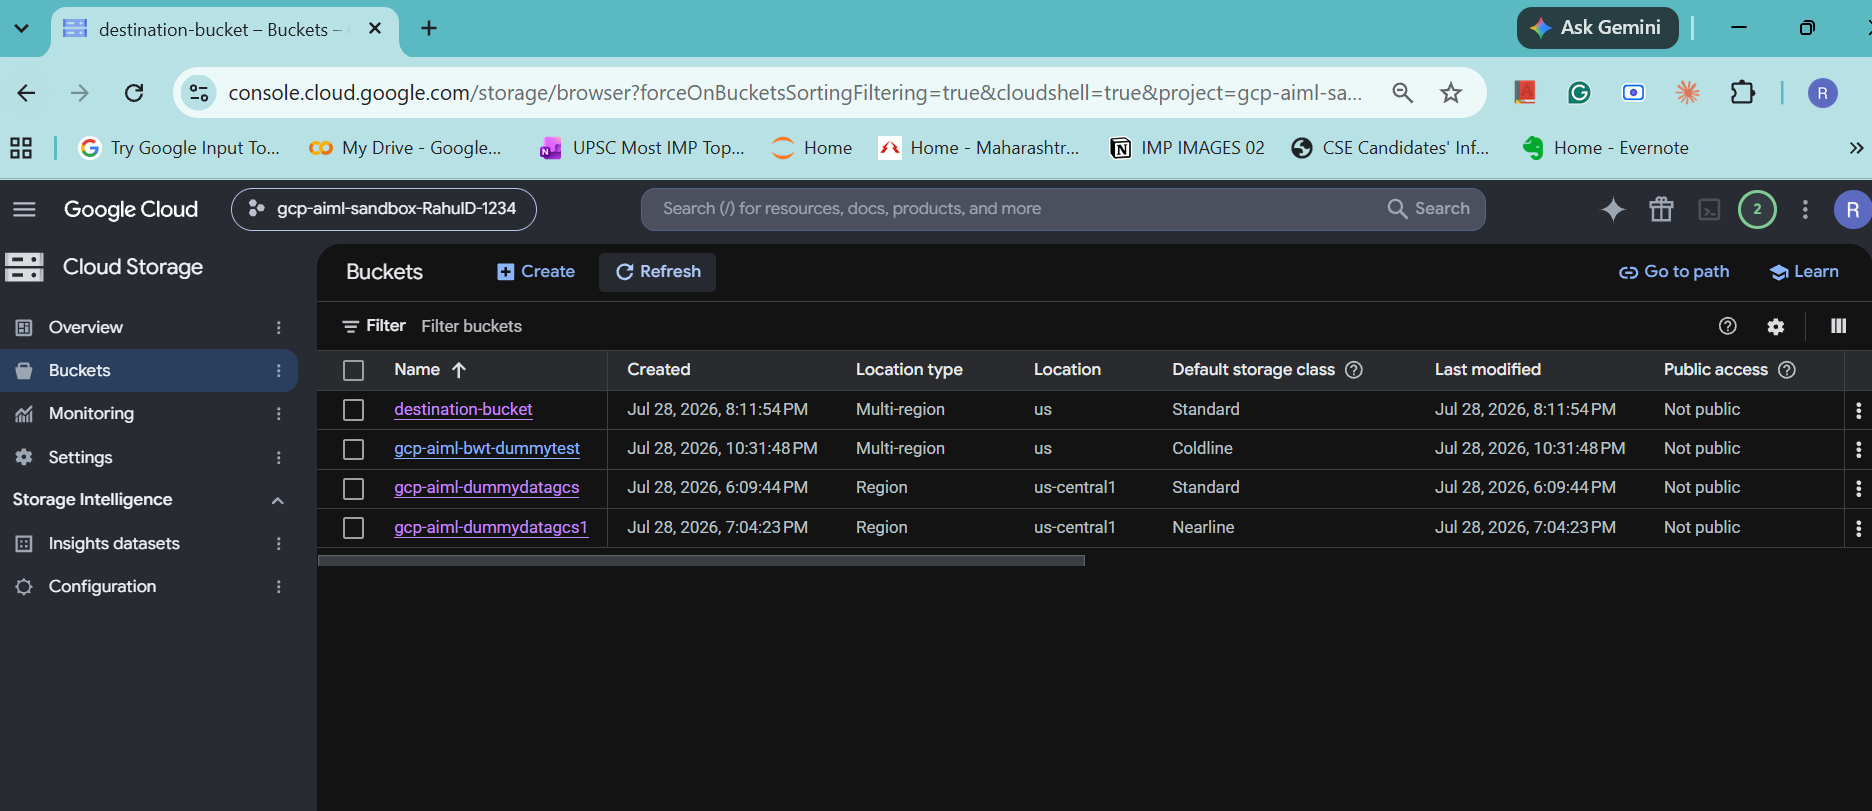
---


---
## 2. List Buckets

```python
from google.cloud import storage

def list_buckets():

    storage_client = storage.Client()

    buckets = storage_client.list_buckets()

    print("\nAvailable Buckets")
    print("-" * 40)

    for bucket in buckets:
        print(bucket.name)


if __name__ == "__main__":
    list_buckets()

```
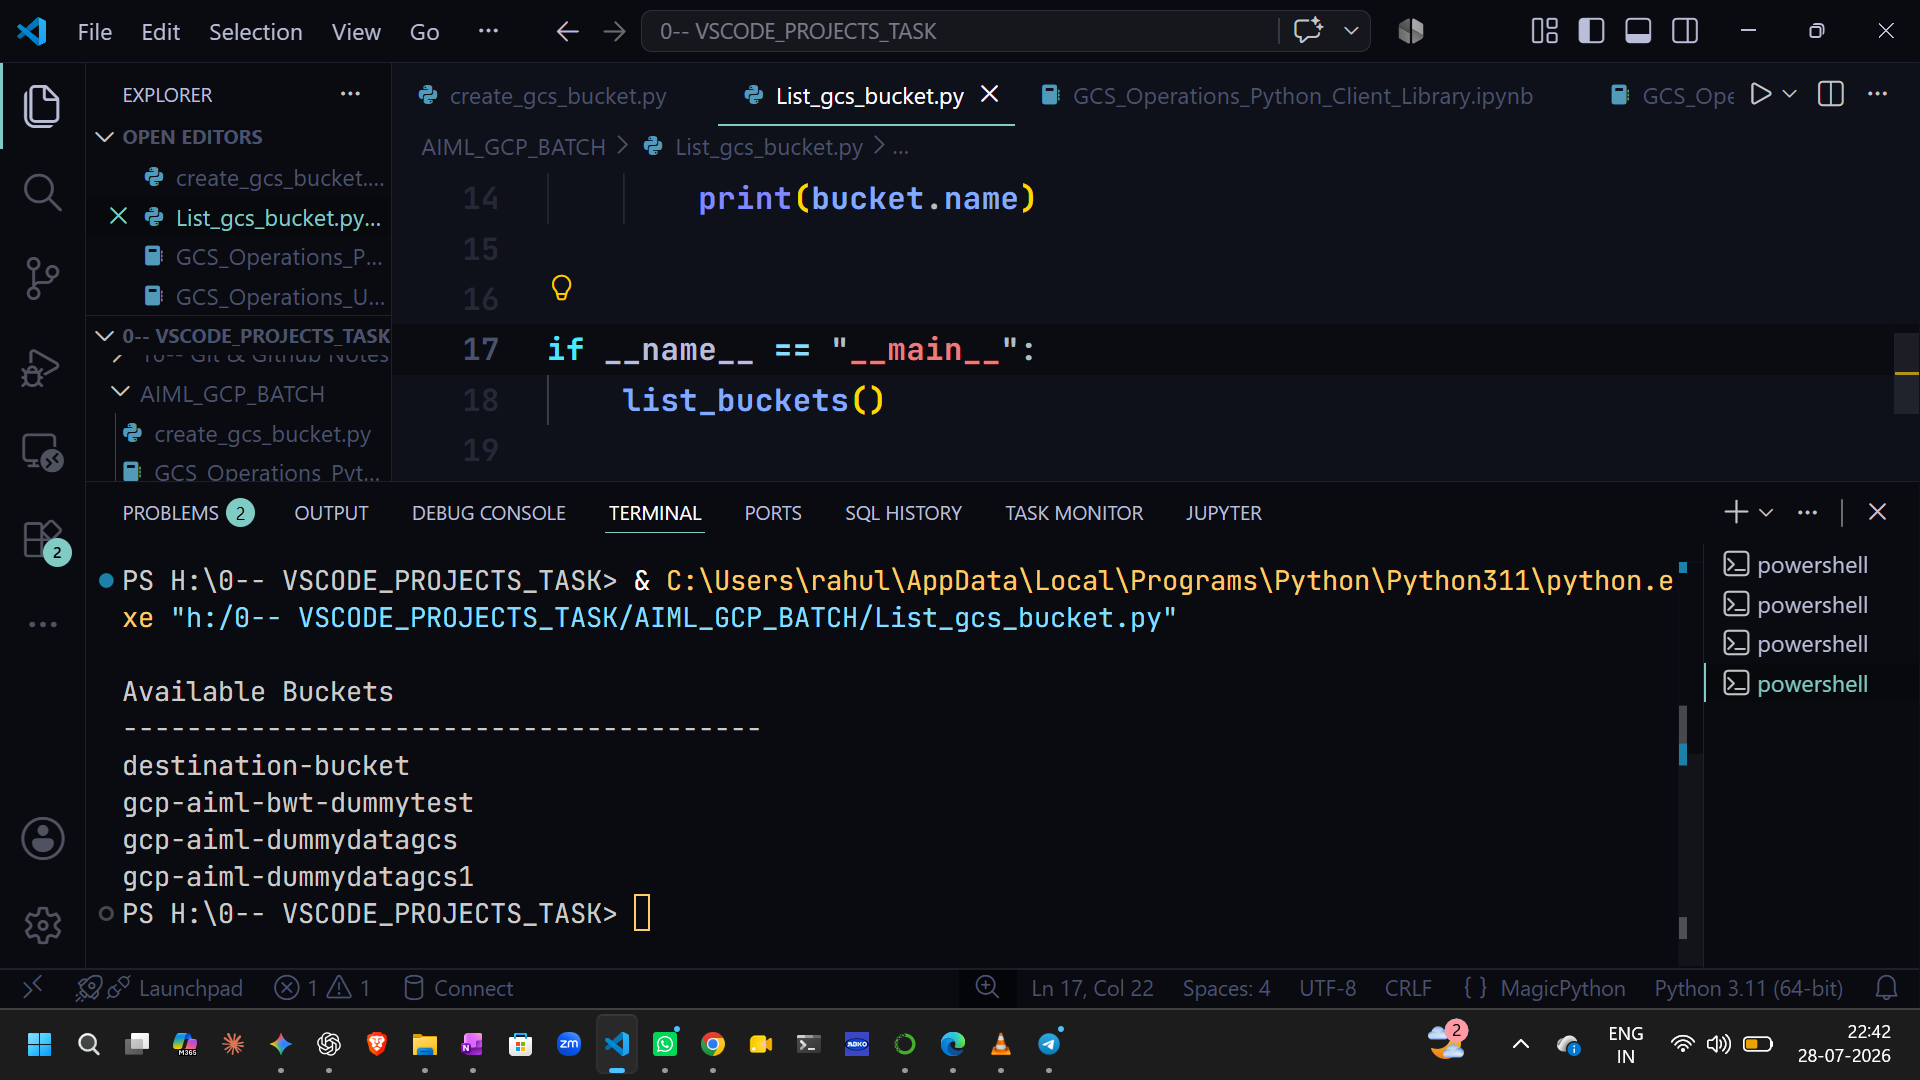

---
## 3. Upload an Object:-

```python
from google.cloud import storage
from pathlib import Path

def upload_blob(bucket_name, source_file_name, destination_blob_name):

    storage_client = storage.Client()

    bucket = storage_client.bucket(bucket_name)

    blob = bucket.blob(destination_blob_name)

    blob.upload_from_filename(str(source_file_name))

    print("File uploaded successfully.")
    print("Bucket:", bucket_name)
    print("Object:", destination_blob_name)


if __name__ == "__main__":

    bucket_name = "gcp-aiml-bwt-dummytest"

    current_folder = Path(__file__).parent

    source_file_name = current_folder / "newfile.txt"

    destination_blob_name = "newfile.txt"

    upload_blob(bucket_name, source_file_name, destination_blob_name)

```
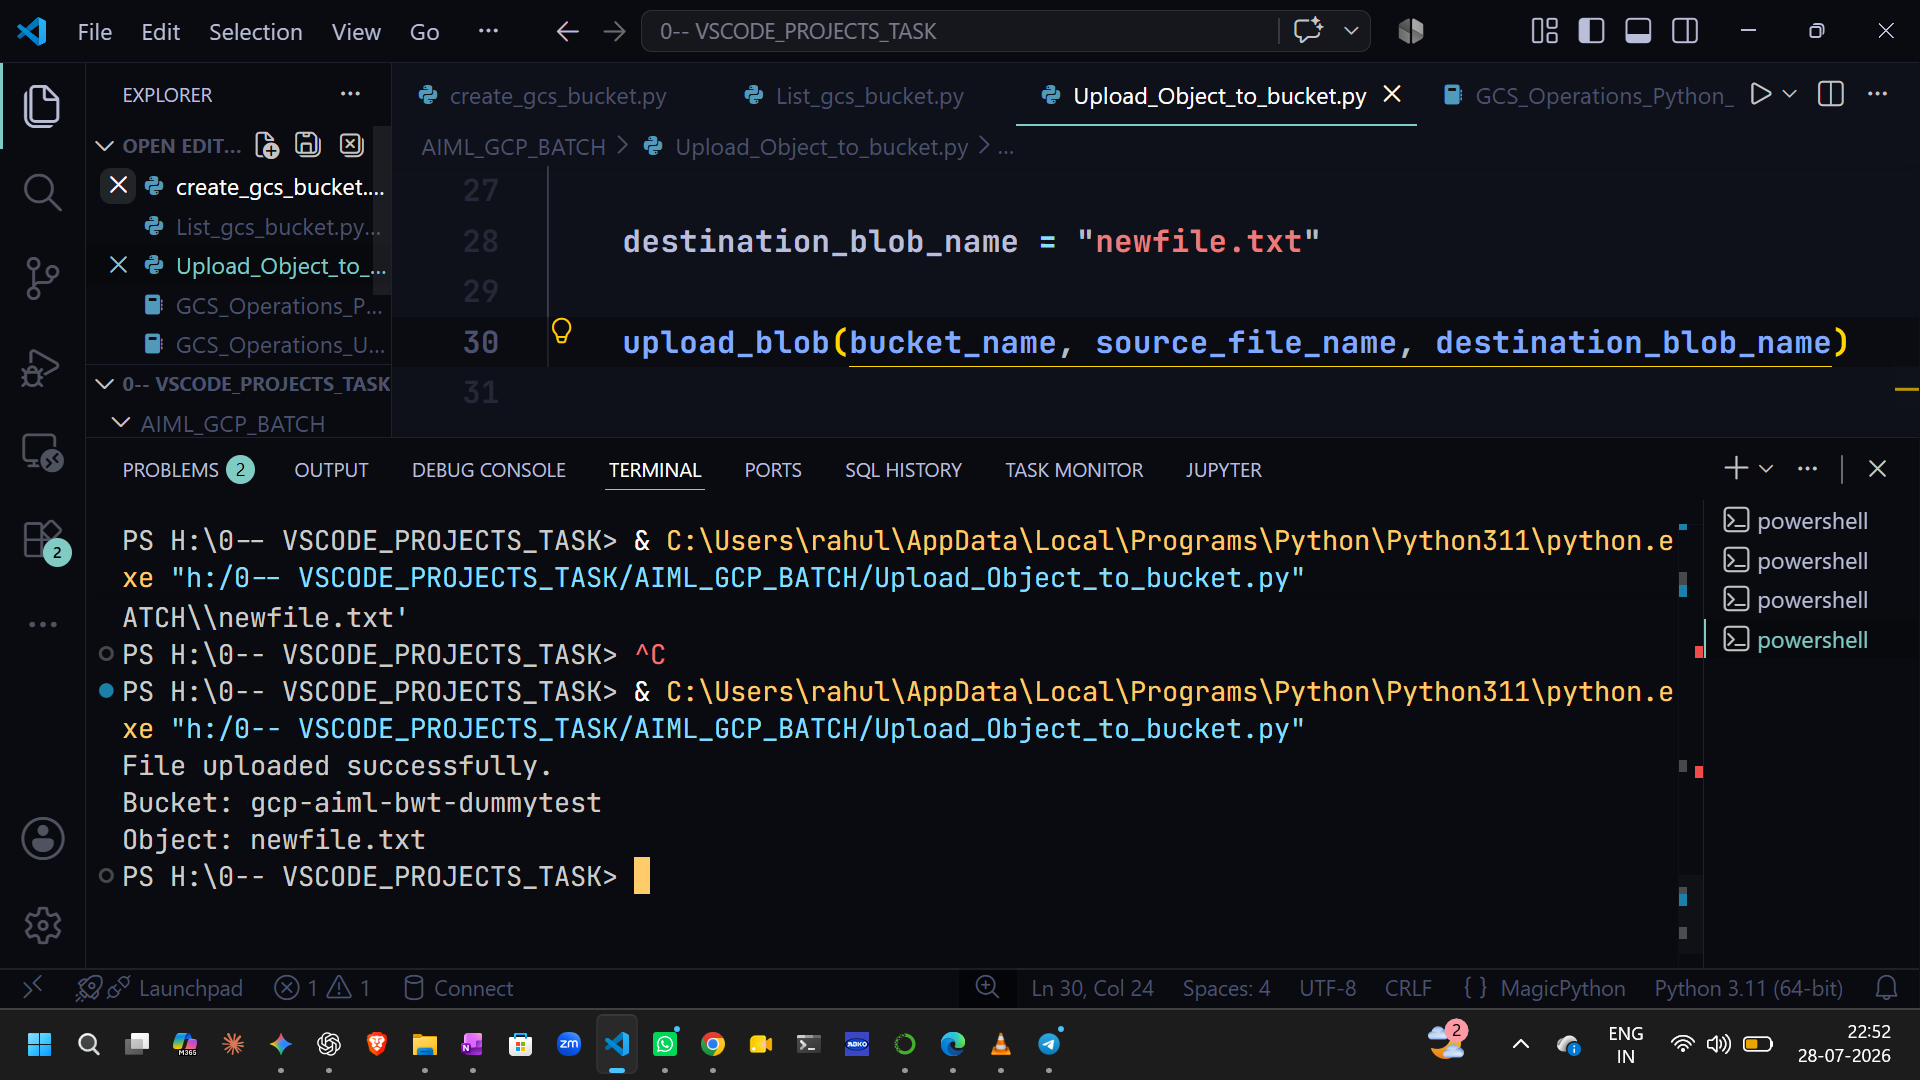

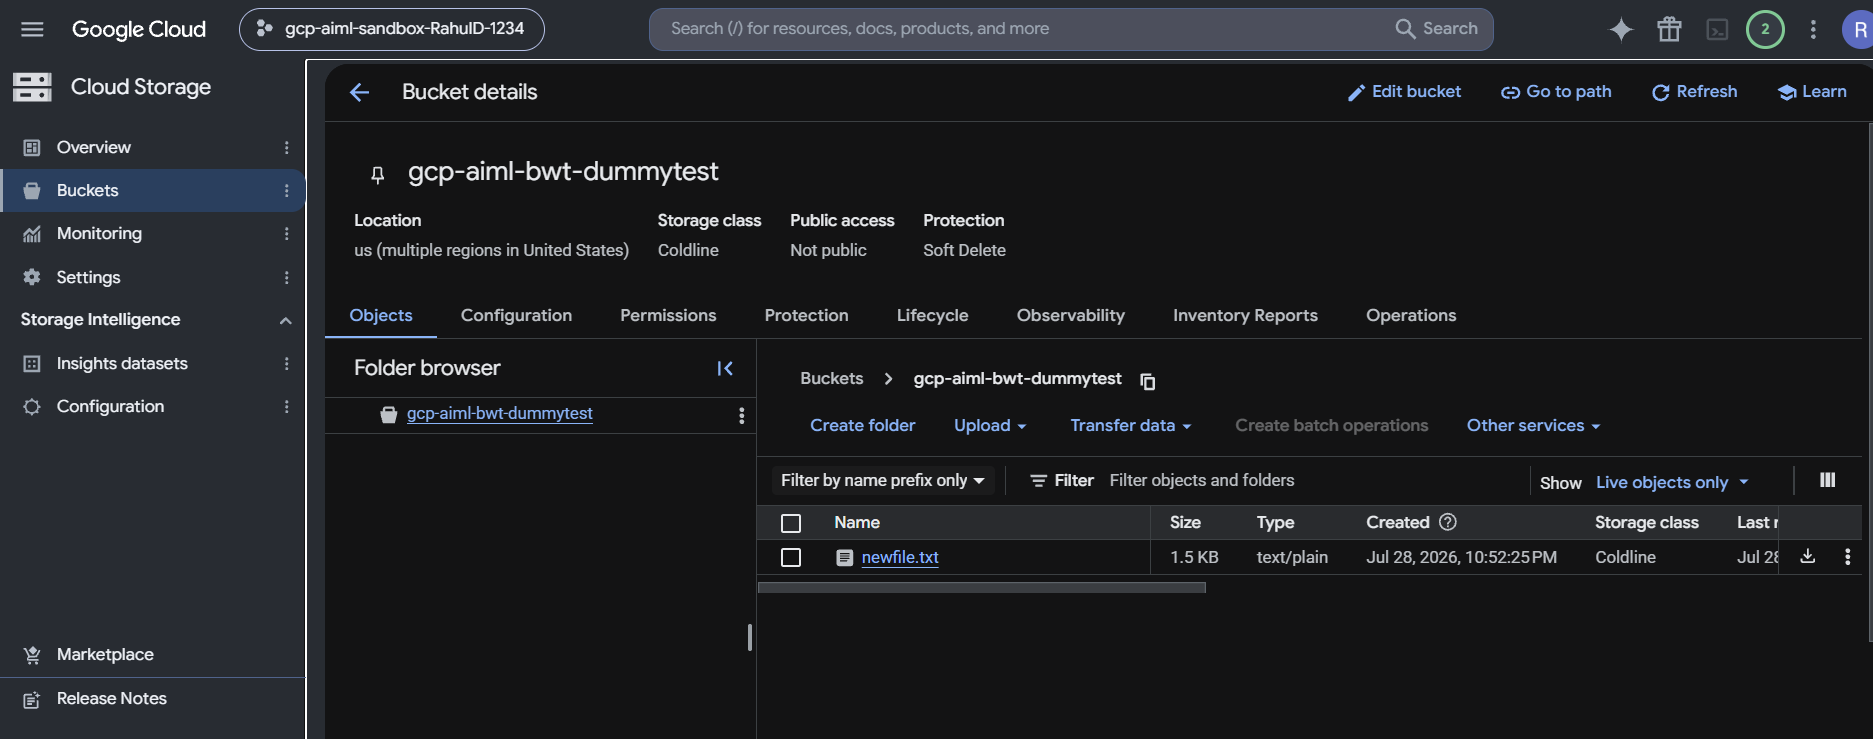

---
## 4. Delete an Object

```python
from google.cloud import storage

def delete_blob(bucket_name, blob_name):

    storage_client = storage.Client()

    bucket = storage_client.bucket(bucket_name)

    blob = bucket.blob(blob_name)

    blob.delete()

    print(f"Object '{blob_name}' deleted successfully.")


if __name__ == "__main__":

    bucket_name = "gcp-aiml-bwt-dummytest"

    blob_name = "newfile.txt"

    delete_blob(bucket_name, blob_name)
```
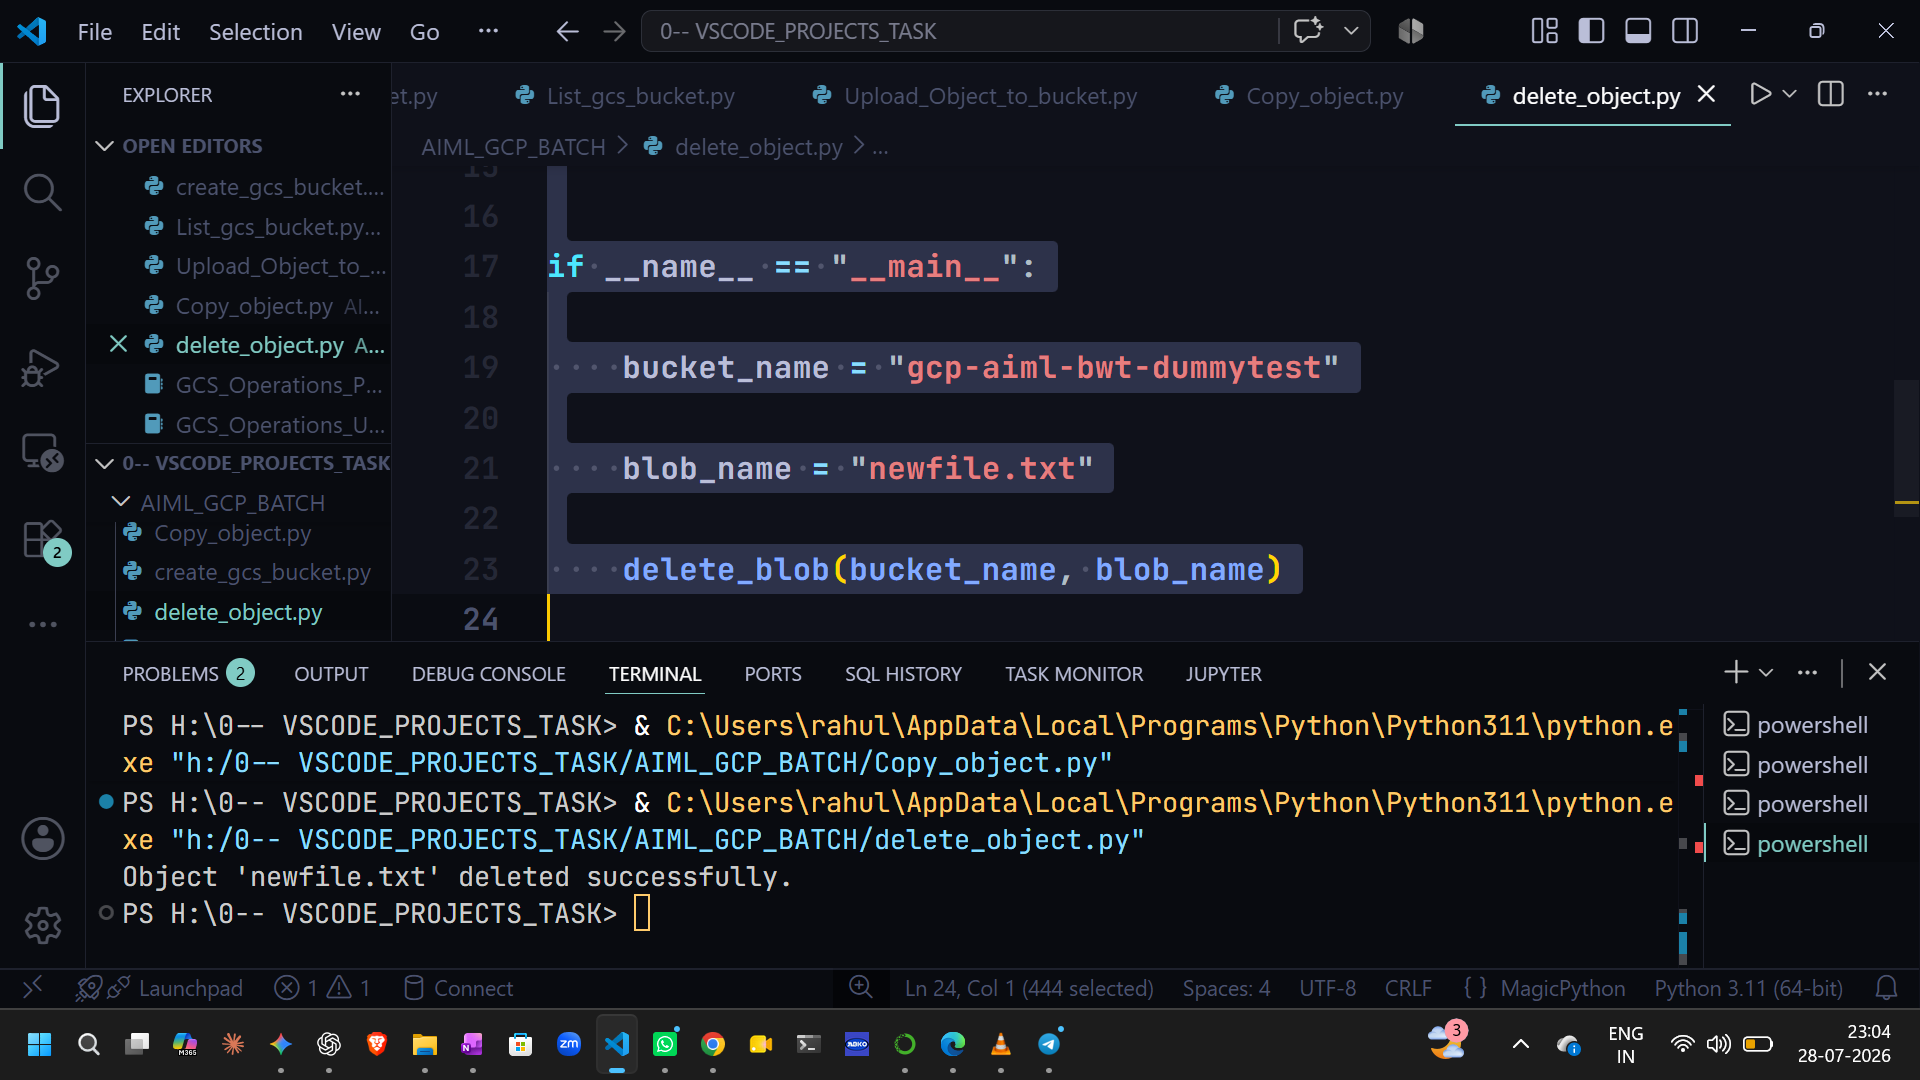

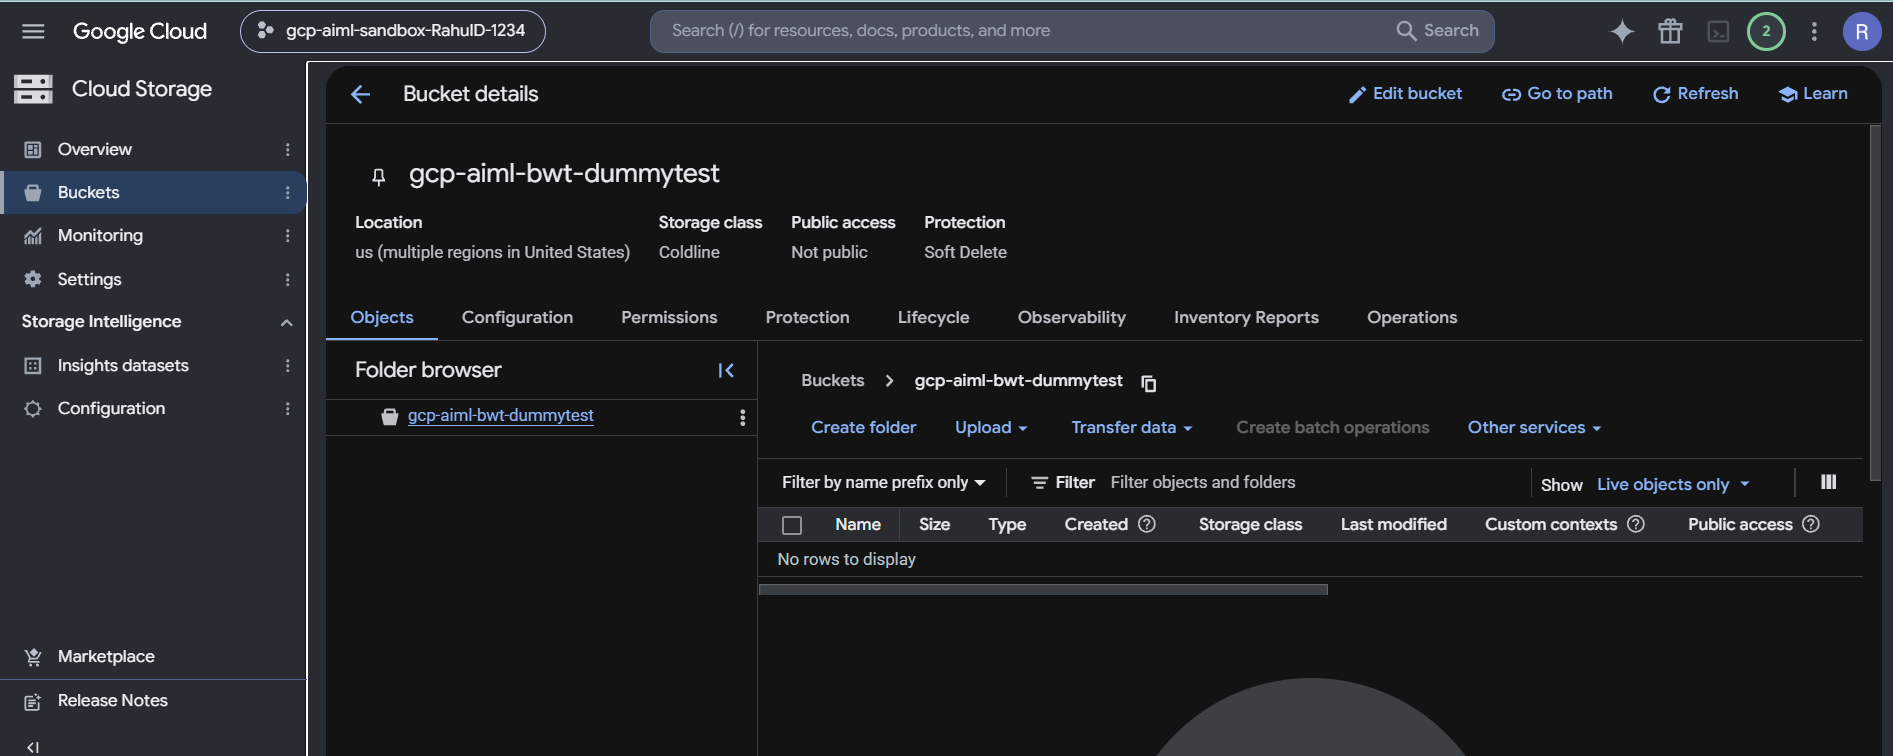

---
## 5. Copy an Object

```python
from google.cloud import storage

def copy_blob(
    source_bucket_name,
    blob_name,
    destination_bucket_name,
    destination_blob_name,
):

    storage_client = storage.Client()

    source_bucket = storage_client.bucket(source_bucket_name)

    source_blob = source_bucket.blob(blob_name)

    destination_bucket = storage_client.bucket(destination_bucket_name)

    copied_blob = source_bucket.copy_blob(
        source_blob,
        destination_bucket,
        destination_blob_name,
    )

    print(
        f"Copied '{copied_blob.name}' from "
        f"'{source_bucket_name}' to "
        f"'{destination_bucket_name}'."
    )


if __name__ == "__main__":

    source_bucket = "gcp-aiml-bwt-dummytest"

    destination_bucket = "gcp-aiml-dummydatagcs1"

    blob_name = "newfile.txt"

    copy_blob(
        source_bucket,
        blob_name,
        destination_bucket,
        blob_name,
    )

```

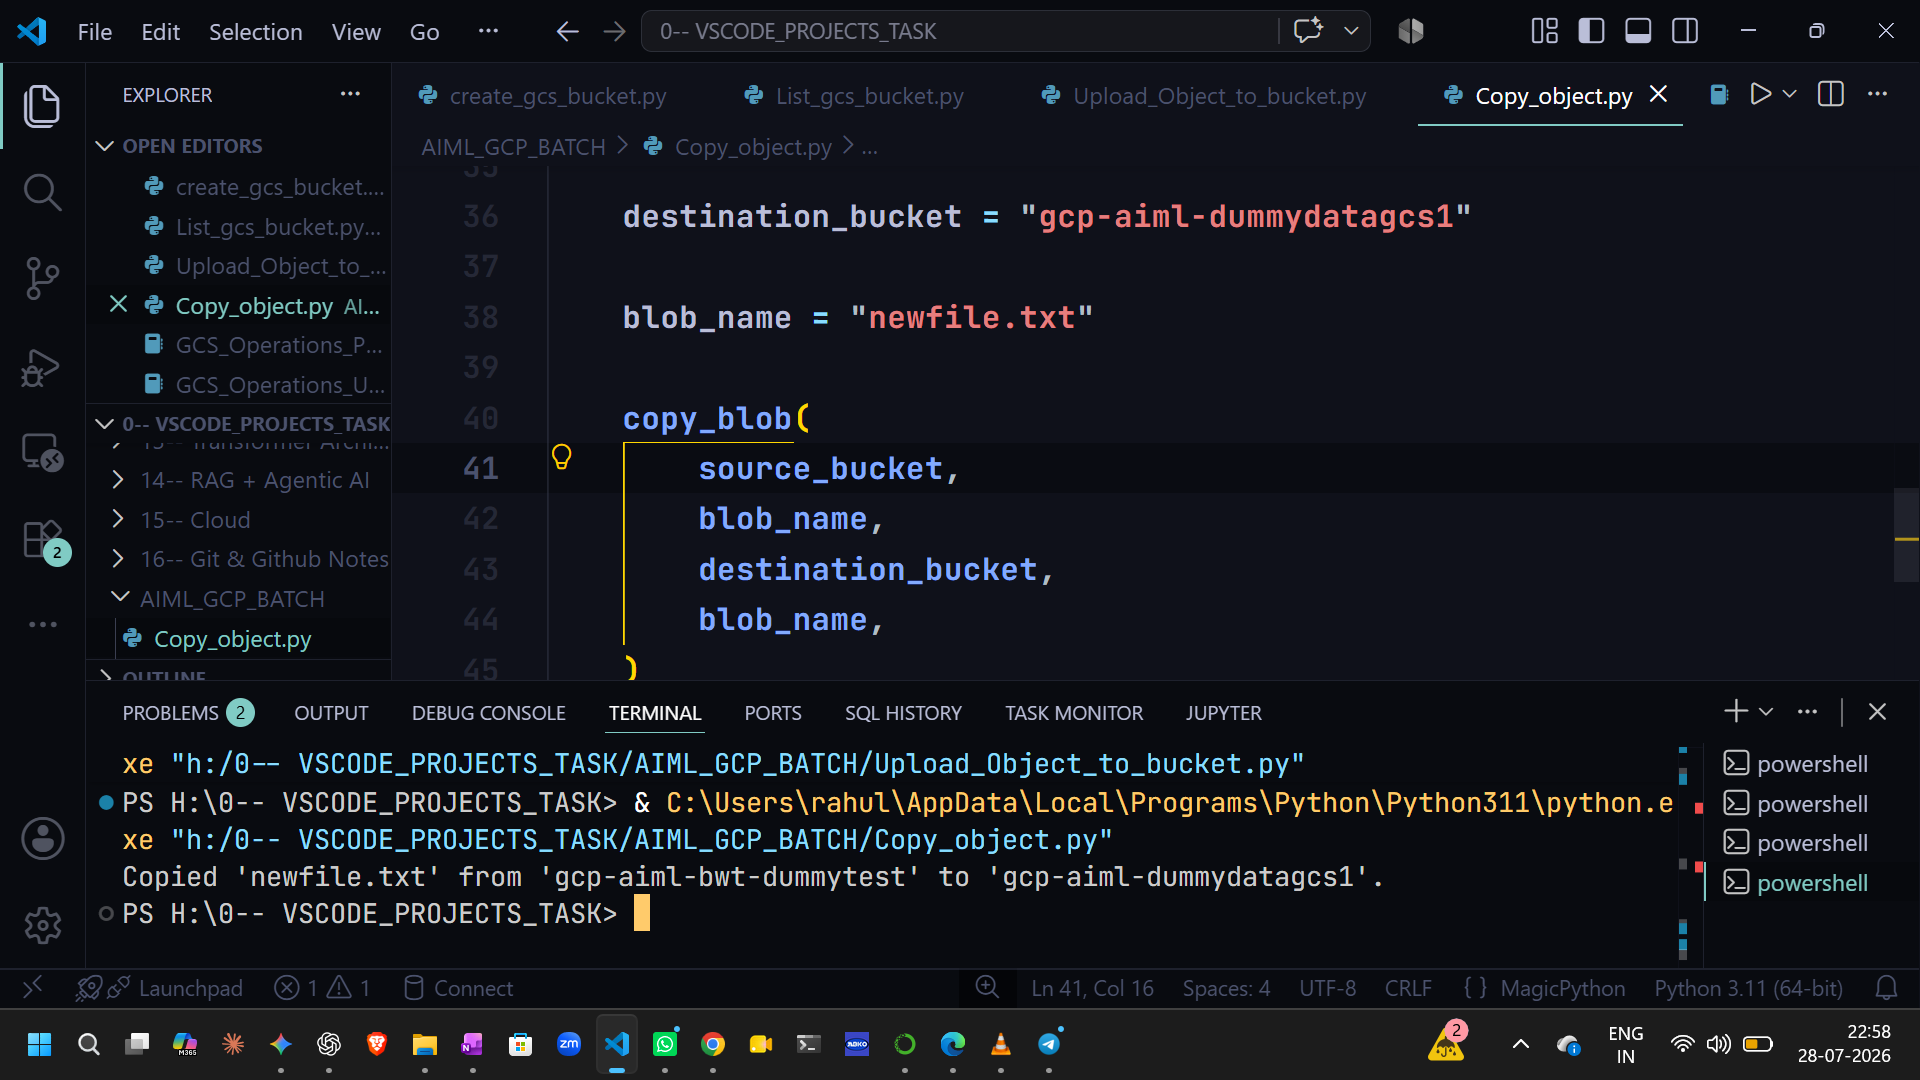    

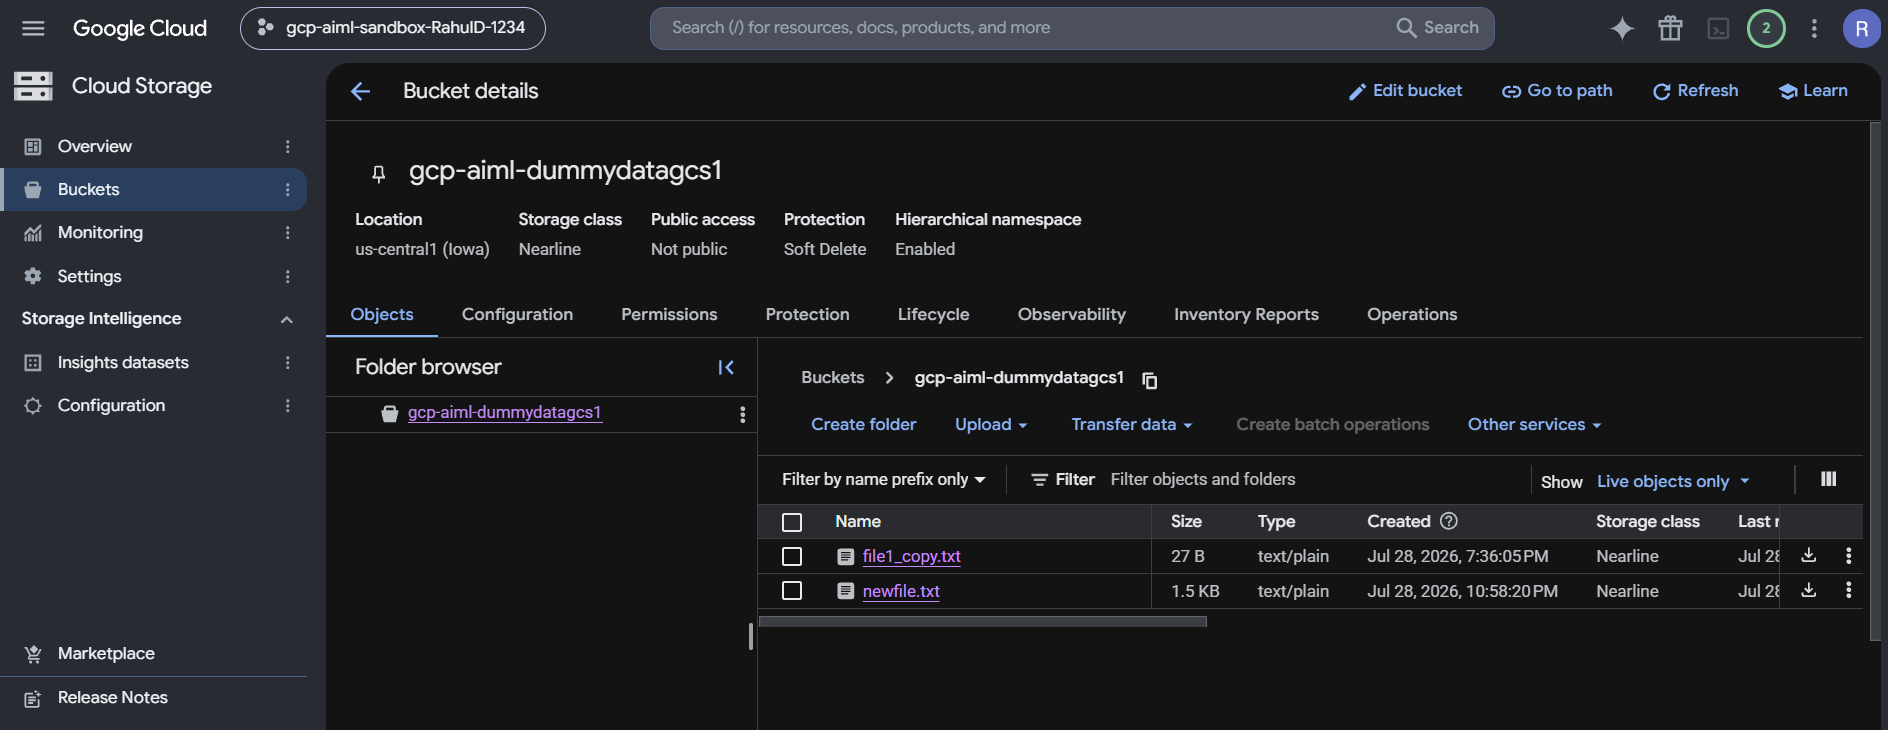

---
## 6. Move an Object
```python
from google.cloud import storage

def move_blob(
    source_bucket_name,
    destination_bucket_name,
    blob_name,
):

    storage_client = storage.Client()

    source_bucket = storage_client.bucket(source_bucket_name)

    source_blob = source_bucket.blob(blob_name)

    destination_bucket = storage_client.bucket(destination_bucket_name)

    source_bucket.copy_blob(
        source_blob,
        destination_bucket,
        blob_name,
    )

    source_blob.delete()

    print(f"'{blob_name}' moved successfully.")


if __name__ == "__main__":

    source_bucket = "gcp-aiml-dummydatagcs1"

    destination_bucket = "gcp-aiml-bwt-dummytest"

    blob_name = "newfile.txt"

    move_blob(
        source_bucket,
        destination_bucket,
        blob_name,
    )

```

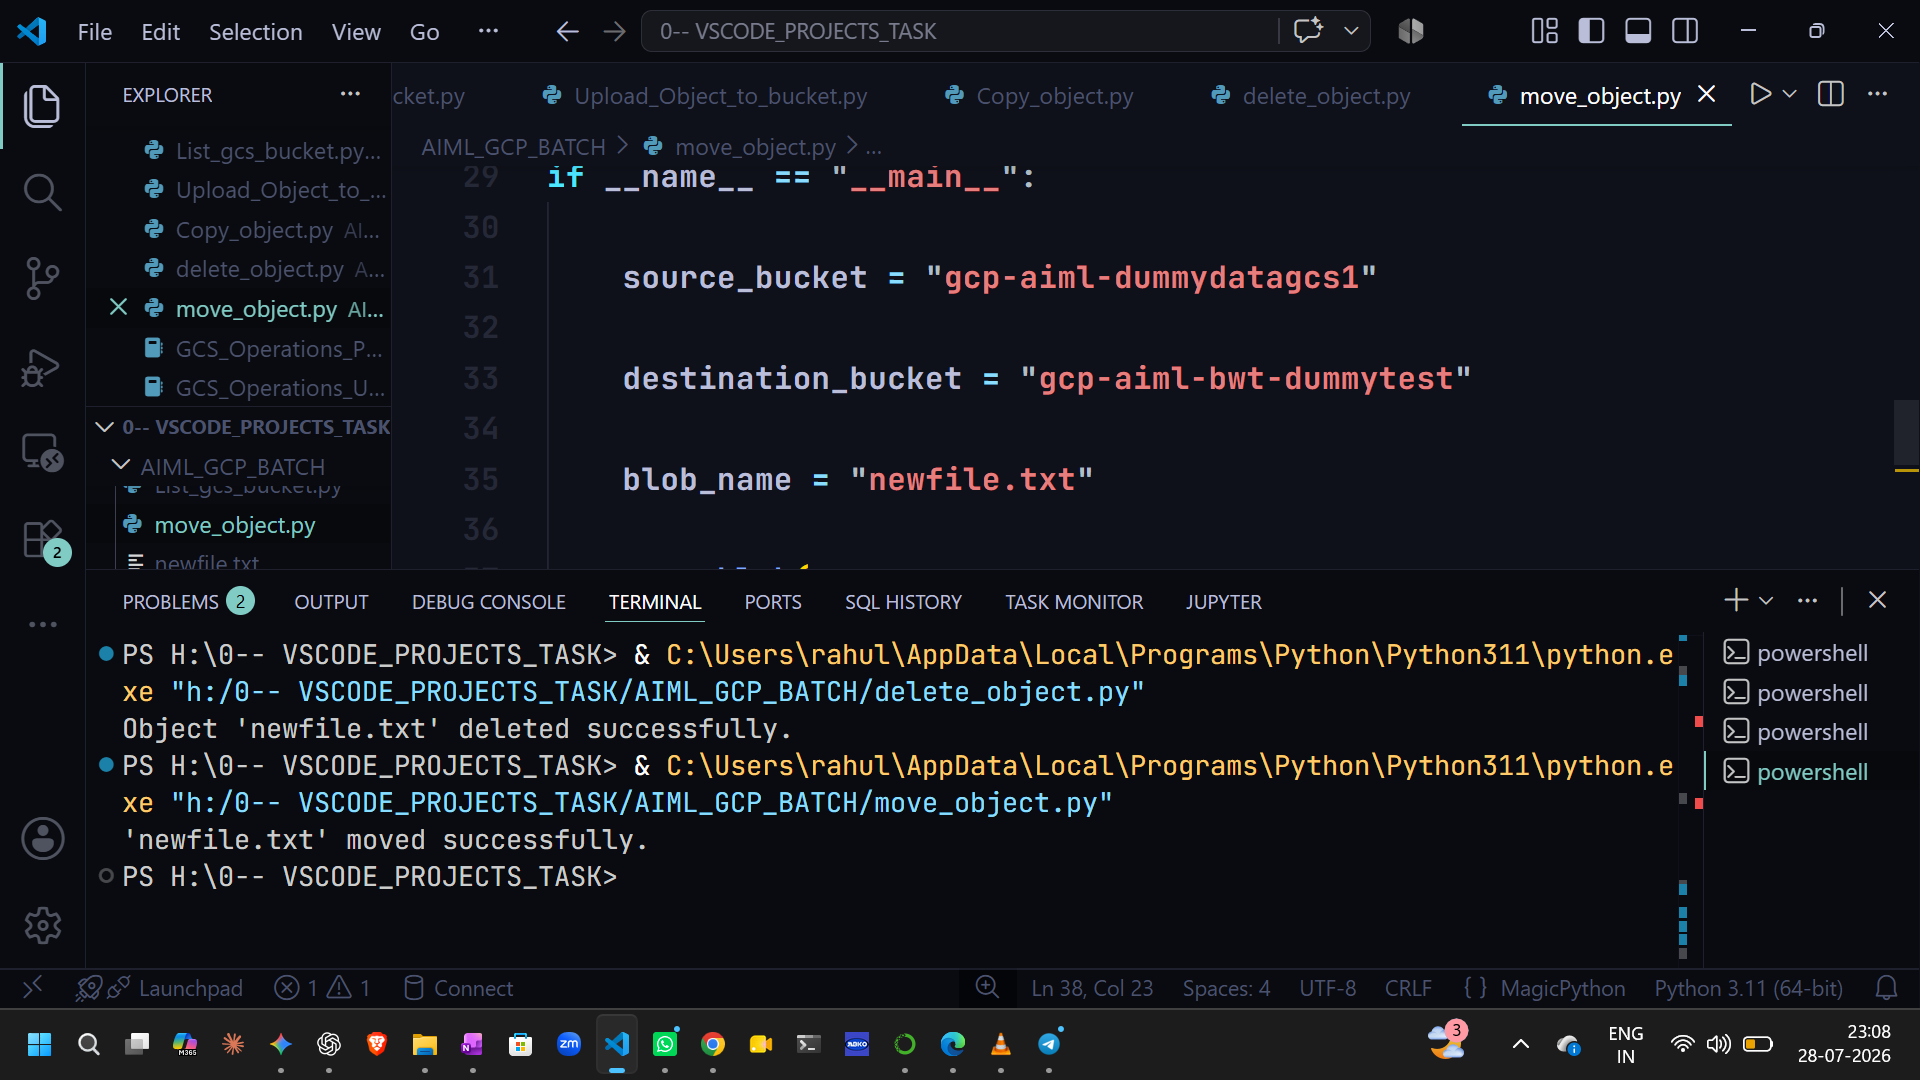

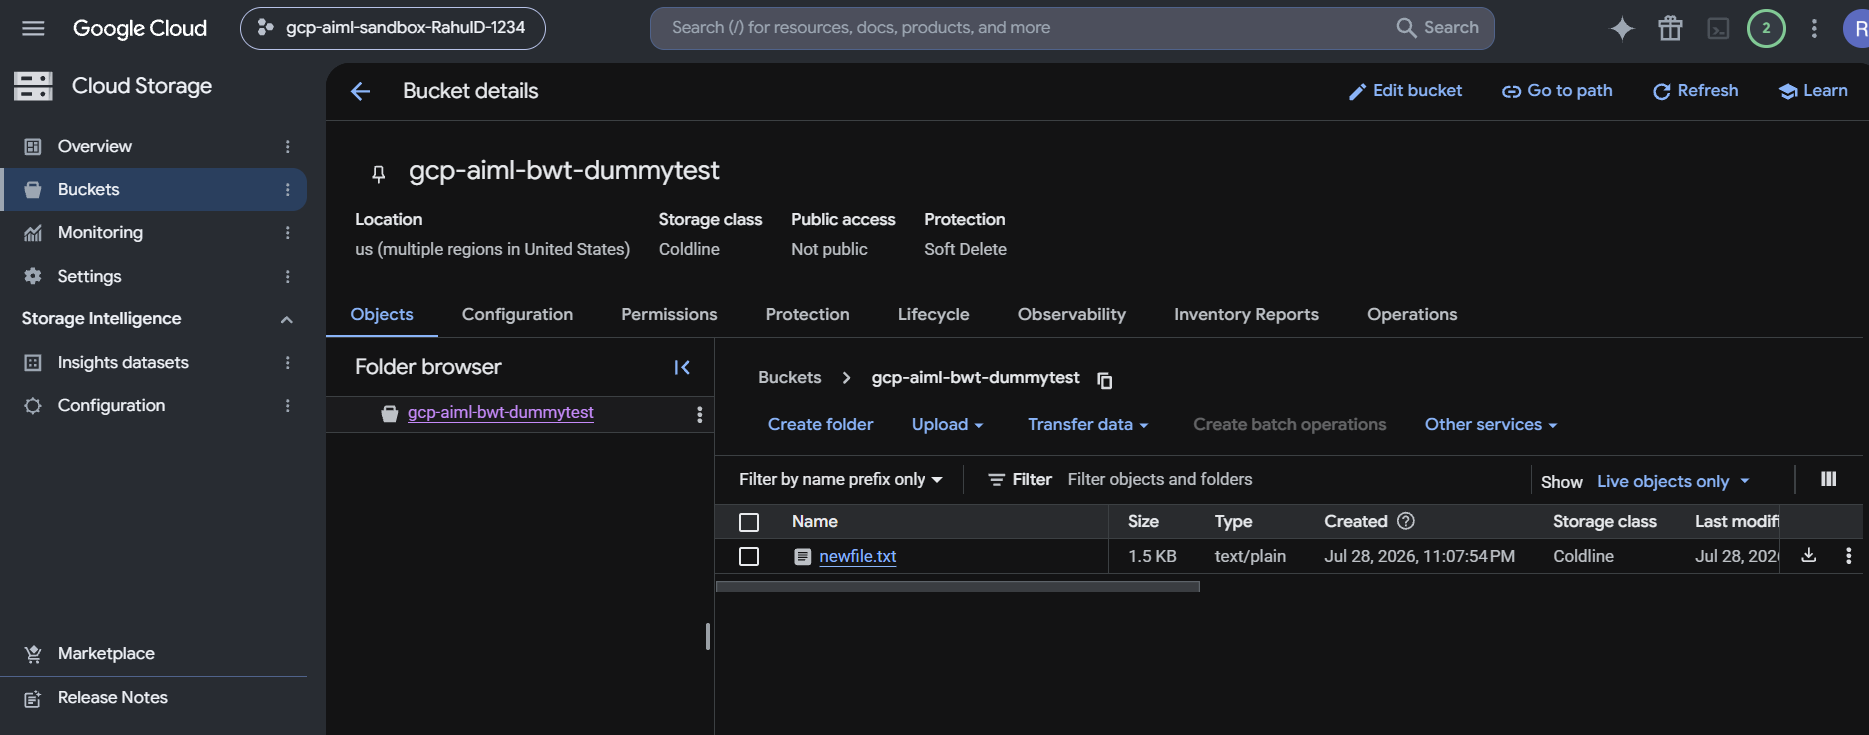

### Python Client Library docs:-
- Python Client Library docs: https://cloud.google.com/python/docs/reference/storage/latest
